# One-stage anchor-based detector: RetinaNet

We train RetinaNet (torchvision, ResNet-50 + FPN, pretrained on COCO) under the same protocol as Faster R-CNN:
the same prepared frames, folds, augmentation, optimizer, modes and metric. Then we compare it with the tuned Faster R-CNN.

## How to run

Run on Google Colab with a T4 GPU. The first cell mounts Google Drive and unpacks data_prepared.zip, results are saved to hw2/retinanet_v2 on the Drive,
and the Faster R-CNN results are read from hw2/frcnn for the comparison at the end.

The notebook works in two steps (see Experiments):

Step 1 compares the experiments with 5-fold cross-validation, step 2 trains the best one on fold 0 with the full protocol.

## Setup

In [7]:
IN_COLAB = "google.colab" in str(get_ipython())
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    !pip install -q -U albumentations pycocotools
    !unzip -q -n /content/drive/MyDrive/hw2/data_prepared.zip -d /content/prep
    !mkdir -p /content/drive/MyDrive/hw2/retinanet_v2

Mounted at /content/drive


In [8]:
import os
os.environ["NO_ALBUMENTATIONS_UPDATE"] = "1"
import contextlib
import io
import json
import math
import random
import shutil
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn.functional as F
import yaml
import albumentations as A
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from torch.utils.data import DataLoader, Dataset
from functools import partial
from torchvision.models.detection import retinanet_resnet50_fpn
from torchvision.models.detection import retinanet as retinanet_module
from torchvision.models.detection.anchor_utils import AnchorGenerator
from torchvision.models.detection.retinanet import RetinaNetClassificationHead
from torchvision.ops import box_iou

In [9]:
DATA_DIR = Path("/content/data")
PREP_DIR = Path("/content/prep/data_prepared")
WORK_DIR = Path("/content/drive/MyDrive/hw2/retinanet_v2")
FRCNN_DIR = Path("/content/drive/MyDrive/hw2/frcnn")

PREP = yaml.safe_load(open(PREP_DIR / "preprocess.yaml"))
SEED = PREP["seed"]
IMG_SIZE = PREP["img_size"]
CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]
IGNORE_COLOR = (114, 114, 114)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

NAVY, LIGHT, MID = "#1B2A4A", "#8EC5E8", "#4A7FB5"
CLASS_COLORS = sns.color_palette("tab10", len(CLASSES))
sns.set_theme(style="whitegrid", palette=[NAVY, LIGHT, MID])


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)
print(DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

cuda Tesla T4


## Training protocol

The same as for Faster R-CNN, so the two detectors can be compared:

- Model: RetinaNet with ResNet-50 + FPN backbone, starting from COCO-pretrained weights. The classification head is replaced with a new one for our 8 classes.
- Input: the model resizes every frame so that its longer side is the input size, without stretching. ImageNet normalization is done inside the model.
- Optimizer: SGD, learning rate 0.01, momentum 0.9, weight decay 0.0001, batch of 4 frames, linear warm-up for 500 steps, then cosine decay.
- Mixed precision (AMP), gradient clipping at 10. A step with a non-finite loss is skipped, so one bad batch cannot break the whole run.
- Augmentation from preprocess.yaml: horizontal flip, zoom-in crop, brightness/contrast/gamma, copy-paste of trucks and buses.
- Up to 500 detections per frame with score ≥ 0.01.
- Evaluation on all validation frames of the fold with pycocotools (mAP, AP50, AP small / medium / large), ignored regions excluded.

| | cv (experiments, all folds) | full (final model) |
|---|---|---|
| input size | 960 px | 1280 px |
| training frames | every 10th frame | every 5th frame |
| epochs | 4 | 8 |
| evaluation | after the last epoch | after every epoch |

In [10]:
MODES = {
    "cv": {"img_size": 960, "frame_step": 10, "epochs": 4, "eval_every_epoch": False},
    "full": {"img_size": IMG_SIZE, "frame_step": 5, "epochs": 8, "eval_every_epoch": True},
}
BATCH_SIZE = 4
LR = 0.01
WARMUP_STEPS = 500
NUM_WORKERS = 2
AMP = DEVICE.type == "cuda"

## Experiments

Each experiment changes one thing compared to the baseline:

- baseline: default torchvision RetinaNet, anchors of 32–812 px with shapes height / width = 0.5, 1, 2 (3 sizes × 3 shapes = 9 anchors per location).
- data_anchors: anchors grounded in our box sizes. We run the same IoU k-means as in the data notebook, but only on the training part of the fold and at the input size of the mode.
  The smallest k-means box becomes the smallest anchor of the first FPN level, and this level now covers everything from it up to 50 px, so there is no gap to the next level (64 px).
  The other levels keep the default sizes, and the three shapes are the typical height / width of the k-means boxes.
  The number of anchors per location stays 9, so the pretrained box head still fits.
  In our first attempt every level was made smaller (the largest anchor became about 330 px instead of 813 px): AP_small went up, but AP for large objects dropped by half and mAP got worse,
  so here only the first level is changed.
- focal_gamma3: focal loss with γ = 3 instead of 2. A larger γ puts even less weight on easy background anchors and more on hard examples;
  in our data the hard ones are small and occluded objects.

FULL_FOLDS lists the folds trained in the full mode in step 2. Fold 0 is enough for the comparison; [0, 1, 2, 3, 4] also gives the out-of-fold metrics of the final model.

In [11]:
CONFIGS = {
    "baseline": {},
    "data_anchors": {"anchors": "kmeans"},
    "focal_gamma3": {"focal_gamma": 3.0},
}

EXPERIMENTS = ["baseline", "data_anchors", "focal_gamma3"]
CV_FOLDS = [0, 1, 2, 3, 4]
FINAL_EXPERIMENT = None
FINAL_FOLD = 0
FULL_FOLDS = [FINAL_FOLD]
PREVIOUS_DIR = None

## Data

Same dataset class as in the Faster R-CNN notebook: frames from data_prepared/images, boxes from the COCO file of the fold, the same augmentation.

In [12]:
aug = PREP["augment"]
BBOX_PARAMS = A.BboxParams(format="pascal_voc", label_fields=["labels"], min_visibility=0.3)


def make_train_transform(img_size):
    return A.Compose(
    [
        A.RandomResizedCrop(size=(img_size, img_size), scale=tuple(aug["crop"]["area"]), ratio=(0.9, 1.1), p=aug["crop"]["p"]),
        A.HorizontalFlip(p=aug["hflip"]),
        A.RandomBrightnessContrast(brightness_limit=aug["brightness_contrast"]["limit"], contrast_limit=aug["brightness_contrast"]["limit"], p=aug["brightness_contrast"]["p"]),
        A.RandomGamma(gamma_limit=tuple(aug["gamma"]["limit"]), p=aug["gamma"]["p"]),
    ],
    bbox_params=BBOX_PARAMS,
    seed=SEED,
    )


def overlaps(box, boxes):
    x1, y1, x2, y2 = box
    return any(x1 < bx2 and bx1 < x2 and y1 < by2 and by1 < y2 for bx1, by1, bx2, by2 in boxes)


class DroneDataset(Dataset):
    def __init__(self, coco_path, train, img_size=IMG_SIZE, frame_step=5):
        coco = json.loads(Path(coco_path).read_text())
        self.images = [im for im in coco["images"] if not train or (im["frame_id"] - 1) % frame_step == 0]
        anns = pd.DataFrame(coco["annotations"])
        anns = anns[anns["iscrowd"] == 0]
        self.anns = {i: g for i, g in anns.groupby("image_id")}
        self.train = train
        self.transform = make_train_transform(img_size)
        size = {im["id"]: im["width"] for im in self.images}
        rare = anns[anns["category_id"].isin([CLASSES.index(c) + 1 for c in aug["copy_paste"]["classes"]])]
        self.rare = rare.assign(file_name=rare["image_id"].map({im["id"]: im["file_name"] for im in self.images}), src_width=rare["image_id"].map(size), src_height=rare["image_id"].map({im["id"]: im["height"] for im in self.images})).dropna(subset=["file_name"])

    def __len__(self):
        return len(self.images)

    def load(self, i):
        info = self.images[i]
        img = cv2.cvtColor(cv2.imread(str(PREP_DIR / info["file_name"])), cv2.COLOR_BGR2RGB)
        g = self.anns.get(info["id"])
        if g is None:
            return info, img, np.zeros((0, 4), np.float32), np.zeros(0, np.int64)
        boxes = np.array(g["bbox"].tolist(), np.float32)
        boxes[:, 2:] += boxes[:, :2]
        boxes = boxes.clip(0, [img.shape[1], img.shape[0], img.shape[1], img.shape[0]])
        return info, img, boxes, g["category_id"].to_numpy(np.int64)

    def copy_paste(self, img, boxes, labels, n):
        H, W = img.shape[:2]
        taken = [tuple(b) for b in boxes]
        new_boxes, new_labels = [], []
        for r in self.rare.sample(min(n, len(self.rare))).itertuples():
            src = cv2.cvtColor(cv2.imread(str(PREP_DIR / r.file_name)), cv2.COLOR_BGR2RGB)
            x, y, w, h = (int(v) for v in r.bbox)
            k = W / r.src_width
            patch = cv2.resize(src[y:y + h, x:x + w], (max(1, round(w * k)), max(1, round(h * k))))
            ph, pw = patch.shape[:2]
            if pw >= W or ph >= H:
                continue
            ty = int(np.clip((y + h / 2) / r.src_height * H - ph / 2, 0, H - ph))
            tx = int(np.random.randint(0, W - pw))
            grey_share = (np.abs(img[ty:ty + ph, tx:tx + pw].astype(int) - IGNORE_COLOR).max(axis=2) <= 3).mean()
            if overlaps((tx, ty, tx + pw, ty + ph), taken) or grey_share > 0.05:
                continue
            img[ty:ty + ph, tx:tx + pw] = patch
            taken.append((tx, ty, tx + pw, ty + ph))
            new_boxes.append([tx, ty, tx + pw, ty + ph])
            new_labels.append(r.category_id)
        if new_boxes:
            boxes = np.vstack([boxes, np.array(new_boxes, np.float32)])
            labels = np.concatenate([labels, np.array(new_labels, np.int64)])
        return img, boxes, labels

    def __getitem__(self, i):
        info, img, boxes, labels = self.load(i)
        if self.train:
            if np.random.rand() < aug["copy_paste"]["p"]:
                img, boxes, labels = self.copy_paste(img, boxes, labels, aug["copy_paste"]["per_frame"])
            out = self.transform(image=img, bboxes=boxes, labels=labels)
            img, boxes, labels = out["image"], np.asarray(out["bboxes"], np.float32).reshape(-1, 4), np.asarray(out["labels"], np.int64)
        target = {"boxes": torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4), "labels": torch.tensor(labels - 1, dtype=torch.int64), "image_id": info["id"]}
        return torch.from_numpy(img.copy()).permute(2, 0, 1).float() / 255, target


def collate(batch):
    return tuple(zip(*batch))


def seed_worker(worker_id):
    seed = SEED + worker_id
    np.random.seed(seed)
    random.seed(seed)
    torch.utils.data.get_worker_info().dataset.transform.set_random_seed(seed)


def make_loaders(fold, mode):
    m = MODES[mode]
    train_ds = DroneDataset(PREP_DIR / "coco" / f"fold{fold}_train.json", train=True, img_size=m["img_size"], frame_step=m["frame_step"])
    val_ds = DroneDataset(PREP_DIR / "coco" / f"fold{fold}_val.json", train=False)
    g = torch.Generator().manual_seed(SEED)
    train_dl = DataLoader(train_ds, BATCH_SIZE, shuffle=True, collate_fn=collate, num_workers=NUM_WORKERS, worker_init_fn=seed_worker, generator=g, drop_last=True)
    val_dl = DataLoader(val_ds, BATCH_SIZE, shuffle=False, collate_fn=collate, num_workers=NUM_WORKERS)
    return train_ds, val_ds, train_dl, val_dl

## Anchors from the data

The same IoU k-means as in the data notebook (YOLOv2 style), fitted only on the training boxes of the fold, after resizing frames to the input size.

In [13]:
def wh_iou(wh, centers):
    inter = np.minimum(wh[:, None, 0], centers[None, :, 0]) * np.minimum(wh[:, None, 1], centers[None, :, 1])
    return inter / (wh.prod(1)[:, None] + centers.prod(1)[None] - inter)


def iou_kmeans(wh, k=9, iters=100):
    rng = np.random.default_rng(SEED)
    centers = wh[rng.choice(len(wh), k, replace=False)]
    for _ in range(iters):
        assign = wh_iou(wh, centers).argmax(1)
        new = np.array([np.median(wh[assign == i], axis=0) for i in range(k)])
        if np.allclose(new, centers):
            break
        centers = new
    return centers[np.argsort(centers.prod(1))]


def train_box_shapes(fold, img_size):
    coco = json.loads((PREP_DIR / "coco" / f"fold{fold}_train.json").read_text())
    longer = {im["id"]: max(im["width"], im["height"]) for im in coco["images"]}
    wh = np.array([[a["bbox"][2], a["bbox"][3]] for a in coco["annotations"] if not a["iscrowd"]], dtype=float)
    scale = np.array([img_size / longer[a["image_id"]] for a in coco["annotations"] if not a["iscrowd"]])
    wh = wh * scale[:, None]
    return wh[np.random.default_rng(SEED).choice(len(wh), min(len(wh), 100_000), replace=False)]


DEFAULT_ANCHORS = (tuple((x, int(x * 2 ** (1 / 3)), int(x * 2 ** (2 / 3))) for x in [32, 64, 128, 256, 512]), ((0.5, 1.0, 2.0),) * 5)


def kmeans_anchors(fold, img_size):
    centers = iou_kmeans(train_box_shapes(fold, img_size))
    base = float(np.sqrt(centers[0].prod()).round(1))
    ratios = np.sort(centers[:, 1] / centers[:, 0])
    shapes = tuple(float(np.median(g).round(2)) for g in np.array_split(ratios, 3))
    first_level = (base, round((base * DEFAULT_ANCHORS[0][0][2]) ** 0.5, 1), DEFAULT_ANCHORS[0][0][2])
    return (first_level,) + DEFAULT_ANCHORS[0][1:], (shapes,) * 5


def anchor_shapes(sizes, ratios):
    return np.array([[s / np.sqrt(r), s * np.sqrt(r)] for level, rs in zip(sizes, ratios) for s in level for r in rs])

In [14]:
cover_rows = []
for name, (sizes, ratios) in {"default": DEFAULT_ANCHORS, "k-means": kmeans_anchors(0, IMG_SIZE)}.items():
    wh = train_box_shapes(0, IMG_SIZE)
    best = wh_iou(wh, anchor_shapes(sizes, ratios)).max(1)
    size = np.sqrt(wh.prod(1))
    cover_rows.append({"anchors": name, "sizes": sizes, "shapes h/w": ratios[0], "mean best IoU": best.mean(),
                       "covered (IoU ≥ 0.5), all": (best >= 0.5).mean(), "covered, boxes < 32 px": (best[size < 32] >= 0.5).mean()})
pd.DataFrame(cover_rows).set_index("anchors").round(3)

,sizes,shapes h/w,mean best IoU,"covered (IoU ≥ 0.5), all","covered, boxes < 32 px"
anchors,,,,,
default,"((32, 40, 50), (64, 80, 101), (128, 161, 203),...","(0.5, 1.0, 2.0)",0.646,0.718,0.486
k-means,"((13.0, 25.5, 50), (64, 80, 101), (128, 161, 2...","(0.57, 1.04, 1.94)",0.721,0.985,0.974


This table shows for the training boxes of fold 0 at 1280 px, how well the best-fitting anchor shape matches each box.

"Covered" is the share of boxes whose best anchor has IoU ≥ 0.5, which is the threshold RetinaNet uses to call an anchor positive.

Default anchors cover 72 % of boxes and only 49 % of boxes under 32 px. Anchors from k-means cover 98.5 % and 97 %, because the first level now starts at 13 px instead of 32 px.

## Model

RetinaNet has no background class: every class gets its own score, and background simply means all 8 scores are low.
So the classification head has 8 outputs and inside the model the classes are numbered 0–7 (the COCO files use 1–8, so we subtract 1 when loading and add 1 back in the predictions).

The focal loss parameters are changed by replacing the focal loss function that the RetinaNet classification head calls. Everything else stays the same.

In [15]:
ORIGINAL_FOCAL = retinanet_module.sigmoid_focal_loss


def build_model(name, img_size, fold=0):
    cfg = CONFIGS[name]
    model = retinanet_resnet50_fpn(weights="DEFAULT", min_size=img_size, max_size=img_size, detections_per_img=500, score_thresh=0.01)
    if cfg.get("anchors") == "kmeans":
        sizes, ratios = kmeans_anchors(fold, img_size)
        model.anchor_generator = AnchorGenerator(sizes, ratios)
    num_anchors = model.head.classification_head.num_anchors
    model.head.classification_head = RetinaNetClassificationHead(256, num_anchors, len(CLASSES))
    gamma = cfg.get("focal_gamma", 2.0)
    retinanet_module.sigmoid_focal_loss = partial(ORIGINAL_FOCAL, alpha=0.25, gamma=gamma) if gamma != 2.0 else ORIGINAL_FOCAL
    return model.to(DEVICE)

## Training and evaluation

In [16]:
def make_optimizer(model, steps_total):
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.SGD(params, lr=LR, momentum=0.9, weight_decay=1e-4)
    warm = lambda s: (s + 1) / WARMUP_STEPS if s < WARMUP_STEPS else 0.5 * (1 + math.cos(math.pi * (s - WARMUP_STEPS) / max(1, steps_total - WARMUP_STEPS)))
    return optimizer, torch.optim.lr_scheduler.LambdaLR(optimizer, warm)


def train_one_epoch(model, loader, optimizer, scheduler, scaler, max_steps=None):
    model.train()
    logs = []
    for step, (images, targets) in enumerate(loader):
        if max_steps and step >= max_steps:
            break
        images = [im.to(DEVICE) for im in images]
        targets = [{"boxes": t["boxes"].to(DEVICE), "labels": t["labels"].to(DEVICE)} for t in targets]
        with torch.autocast(DEVICE.type, enabled=AMP):
            losses = model(images, targets)
            loss = sum(losses.values())
        optimizer.zero_grad()
        if not torch.isfinite(loss):
            scheduler.step()
            continue
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        logs.append({k: v.item() for k, v in losses.items()})
    return pd.DataFrame(logs).mean()


@torch.no_grad()
def predict(model, loader, max_batches=None):
    model.eval()
    dets = []
    for b, (images, targets) in enumerate(loader):
        if max_batches and b >= max_batches:
            break
        with torch.autocast(DEVICE.type, enabled=AMP):
            outputs = model([im.to(DEVICE) for im in images])
        for t, o in zip(targets, outputs):
            boxes = o["boxes"].float().cpu().numpy()
            boxes[:, 2:] -= boxes[:, :2]
            dets += [{"image_id": t["image_id"], "category_id": int(l) + 1, "bbox": [round(float(v), 2) for v in bb], "score": round(float(s), 4)} for bb, l, s in zip(boxes, o["labels"].tolist(), o["scores"].tolist())]
    return dets


def coco_metrics(gt_path, dets):
    with contextlib.redirect_stdout(io.StringIO()):
        gt = COCO(str(gt_path))
        if not dets:
            return {k: 0.0 for k in ["mAP", "AP50", "AP_small", "AP_medium", "AP_large"]}, None
        ev = COCOeval(gt, gt.loadRes(dets), "bbox")
        ev.params.maxDets = [1, 100, 500]
        ev.evaluate()
        ev.accumulate()
        ev.summarize()
    s = ev.stats
    return {"mAP": float(s[0]), "AP50": float(s[1]), "AP_small": float(s[3]), "AP_medium": float(s[4]), "AP_large": float(s[5])}, ev

In [17]:
RESULTS = WORK_DIR / "results.csv"


def finished(name, fold, mode):
    if not RESULTS.exists():
        return False
    r = pd.read_csv(RESULTS)
    return ((r["experiment"] == name) & (r["fold"] == fold) & (r["mode"] == mode) & (r["epoch"] == MODES[mode]["epochs"])).any()


def run(name, fold, mode):
    set_seed(SEED)
    m = MODES[mode]
    tag = f"{name}_{mode}_fold{fold}"
    train_ds, val_ds, train_dl, val_dl = make_loaders(fold, mode)
    model = build_model(name, m["img_size"], fold)
    optimizer, scheduler = make_optimizer(model, m["epochs"] * len(train_dl))
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=AMP)
    gt_path = PREP_DIR / "coco" / f"fold{fold}_val.json"
    best = -1.0
    for epoch in range(1, m["epochs"] + 1):
        start = time.time()
        losses = train_one_epoch(model, train_dl, optimizer, scheduler, scaler)
        if not m["eval_every_epoch"] and epoch < m["epochs"]:
            print(f"{tag} epoch {epoch}: loss {losses.sum():.3f}  ({(time.time() - start) / 60:.1f} min)")
            continue
        dets = predict(model, val_dl)
        metrics, _ = coco_metrics(gt_path, dets)
        row = {"experiment": name, "mode": mode, "fold": fold, "epoch": epoch, **metrics, "loss": losses.sum(), **losses.to_dict(), "minutes": (time.time() - start) / 60}
        pd.DataFrame([row]).to_csv(RESULTS, mode="a", header=not RESULTS.exists(), index=False)
        print(f"{tag} epoch {epoch}: mAP {metrics['mAP']:.4f}  AP50 {metrics['AP50']:.4f}  AP_small {metrics['AP_small']:.4f}  ({row['minutes']:.1f} min)")
        if metrics["mAP"] > best:
            best = metrics["mAP"]
            torch.save(model.state_dict(), WORK_DIR / f"{tag}.pt")
            (WORK_DIR / f"{tag}_val_dets.json").write_text(json.dumps(dets))
    return model


def out_of_fold(name, mode, folds, directory=WORK_DIR):
    offset, images, anns, all_dets = 0, [], [], []
    for f in folds:
        gt = json.loads((PREP_DIR / "coco" / f"fold{f}_val.json").read_text())
        d = json.loads((directory / f"{name}_{mode}_fold{f}_val_dets.json").read_text())
        images += [{**im, "id": im["id"] + offset} for im in gt["images"]]
        anns += [{**a, "id": len(anns) + j + 1, "image_id": a["image_id"] + offset} for j, a in enumerate(gt["annotations"])]
        all_dets += [{**x, "image_id": x["image_id"] + offset} for x in d]
        offset += max(im["id"] for im in gt["images"])
    (WORK_DIR / "oof_gt.json").write_text(json.dumps({"images": images, "annotations": anns, "categories": gt["categories"]}))
    return coco_metrics(WORK_DIR / "oof_gt.json", all_dets)[0]

Results of a previous session (optional). If PREVIOUS_DIR points to the output of an earlier run of this notebook,
its results.csv, weights and predictions are copied to WORK_DIR, and finished runs are skipped.

In [18]:
if PREVIOUS_DIR:
    for f in Path(PREVIOUS_DIR).glob("*"):
        if f.suffix in {".pt", ".json", ".csv"} and not (WORK_DIR / f.name).exists():
            shutil.copy(f, WORK_DIR / f.name)
    print(pd.read_csv(RESULTS).groupby(["experiment", "mode"])["fold"].unique() if RESULTS.exists() else "no previous results")

## Step 1: cross-validation of the experiments

In [19]:
for name in EXPERIMENTS:
    for fold in CV_FOLDS:
        if not finished(name, fold, "cv"):
            run(name, fold, "cv")

Downloading: "https://download.pytorch.org/models/retinanet_resnet50_fpn_coco-eeacb38b.pth" to /root/.cache/torch/hub/checkpoints/retinanet_resnet50_fpn_coco-eeacb38b.pth


100%|██████████| 130M/130M [00:00<00:00, 164MB/s]


baseline_cv_fold4 epoch 1: loss 1.272  (5.0 min)
baseline_cv_fold4 epoch 2: loss 0.779  (4.9 min)
baseline_cv_fold4 epoch 3: loss 0.635  (5.0 min)
baseline_cv_fold4 epoch 4: mAP 0.0825  AP50 0.1683  AP_small 0.0087  (8.2 min)
data_anchors_cv_fold0 epoch 1: loss 1.195  (4.8 min)
data_anchors_cv_fold0 epoch 2: loss 0.704  (4.8 min)
data_anchors_cv_fold0 epoch 3: loss 0.600  (4.8 min)
data_anchors_cv_fold0 epoch 4: mAP 0.0960  AP50 0.1890  AP_small 0.0316  (7.9 min)
data_anchors_cv_fold1 epoch 1: loss 1.195  (4.9 min)
data_anchors_cv_fold1 epoch 2: loss 0.681  (4.9 min)
data_anchors_cv_fold1 epoch 3: loss 0.591  (4.9 min)
data_anchors_cv_fold1 epoch 4: mAP 0.0911  AP50 0.1919  AP_small 0.0234  (7.5 min)
data_anchors_cv_fold2 epoch 1: loss 1.213  (4.6 min)
data_anchors_cv_fold2 epoch 2: loss 0.709  (4.6 min)
data_anchors_cv_fold2 epoch 3: loss 0.590  (4.6 min)
data_anchors_cv_fold2 epoch 4: mAP 0.0901  AP50 0.1926  AP_small 0.0165  (8.2 min)
data_anchors_cv_fold3 epoch 1: loss 1.184  (4.8 

### Cross-validation results

For every experiment: mean and standard deviation of the metrics over the folds, the out-of-fold mAP (all validation predictions of all folds evaluated together),
and the difference from the baseline.

In [20]:
metric_cols = ["mAP", "AP50", "AP_small", "AP_medium", "AP_large"]
results = pd.read_csv(RESULTS)
cv_rows = results[(results["mode"] == "cv") & (results["epoch"] == MODES["cv"]["epochs"])].drop_duplicates(["experiment", "fold"], keep="last")
cv_mean = cv_rows.groupby("experiment")[metric_cols].agg(["mean", "std"]).round(4)
oof = pd.DataFrame({name: out_of_fold(name, "cv", sorted(g["fold"])) for name, g in cv_rows.groupby("experiment")}).T.add_prefix("OOF ")
if "baseline" in oof.index:
    oof = oof.join((oof - oof.loc["baseline"]).add_prefix("Δ "))
display(cv_mean)
oof.round(4)

mAP            AP50         AP_small         AP_medium  \
                mean     std    mean     std     mean     std      mean   
experiment                                                                
baseline      0.0867  0.0082  0.1806  0.0179   0.0187  0.0082    0.0917   
data_anchors  0.0886  0.0058  0.1814  0.0140   0.0188  0.0088    0.0874   
focal_gamma3  0.0751  0.0079  0.1577  0.0167   0.0144  0.0056    0.0798   

                     AP_large          
                 std     mean     std  
experiment                             
baseline      0.0112   0.2376  0.0266  
data_anchors  0.0109   0.2533  0.0235  
focal_gamma3  0.0095   0.2134  0.0284

,OOF mAP,OOF AP50,OOF AP_small,OOF AP_medium,OOF AP_large,Δ OOF mAP,Δ OOF AP50,Δ OOF AP_small,Δ OOF AP_medium,Δ OOF AP_large
baseline,0.0813,0.1723,0.0154,0.0887,0.2151,0.0000,0.0000,0.0000,0.0000,0.0000
data_anchors,0.0827,0.1727,0.0161,0.0856,0.2257,0.0013,0.0004,0.0007,-0.0031,0.0106
focal_gamma3,0.0711,0.1513,0.0119,0.0772,0.1980,-0.0102,-0.0210,-0.0036,-0.0115,-0.0170


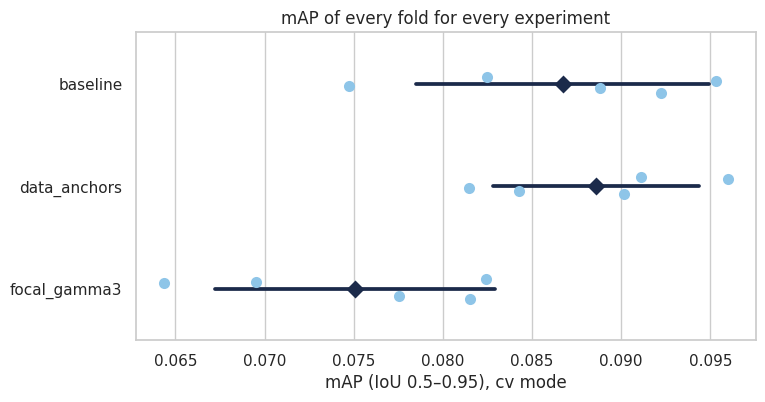

In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.stripplot(cv_rows, x="mAP", y="experiment", order=EXPERIMENTS, color=LIGHT, size=8, jitter=0.1, ax=ax)
sns.pointplot(cv_rows, x="mAP", y="experiment", order=EXPERIMENTS, color=NAVY, linestyle="none", errorbar="sd", markers="D", ax=ax)
ax.set(xlabel="mAP (IoU 0.5–0.95), cv mode", ylabel="", title="mAP of every fold for every experiment")
plt.show()

data_anchors has the best mean mAP, then baseline and focal_gamma3. data_anchors is only a little better and the difference is within the fold variation, while γ = 3 clearly makes things worse.

## Step 2: the final model in the full mode

In [22]:
final_name = FINAL_EXPERIMENT or oof["OOF mAP"].idxmax()
print("final experiment:", final_name)
for fold in FULL_FOLDS:
    if not finished(final_name, fold, "full"):
        run(final_name, fold, "full")
if len(FULL_FOLDS) > 1:
    print("full mode, out-of-fold:", {k: round(v, 4) for k, v in out_of_fold(final_name, "full", FULL_FOLDS).items()})

final experiment: data_anchors
data_anchors_full_fold0 epoch 1: mAP 0.0741  AP50 0.1509  AP_small 0.0240  (19.1 min)
data_anchors_full_fold0 epoch 2: mAP 0.1192  AP50 0.2327  AP_small 0.0445  (19.4 min)
data_anchors_full_fold0 epoch 3: mAP 0.1431  AP50 0.2788  AP_small 0.0538  (19.5 min)
data_anchors_full_fold0 epoch 4: mAP 0.1561  AP50 0.3078  AP_small 0.0697  (19.1 min)
data_anchors_full_fold0 epoch 5: mAP 0.1723  AP50 0.3290  AP_small 0.0587  (19.0 min)
data_anchors_full_fold0 epoch 6: mAP 0.1808  AP50 0.3426  AP_small 0.0651  (19.1 min)
data_anchors_full_fold0 epoch 7: mAP 0.1806  AP50 0.3456  AP_small 0.0657  (19.0 min)
data_anchors_full_fold0 epoch 8: mAP 0.1823  AP50 0.3479  AP_small 0.0676  (19.0 min)


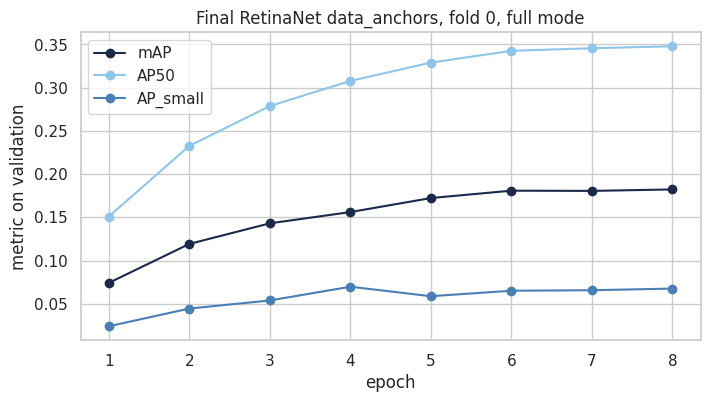

,epoch,mAP,AP50,AP_small,AP_medium,AP_large
22,8,0.1823,0.3479,0.0676,0.1742,0.4505


In [23]:
results = pd.read_csv(RESULTS)
full_rows = results[(results["mode"] == "full") & (results["experiment"] == final_name) & (results["fold"] == FINAL_FOLD)].drop_duplicates("epoch", keep="last")

fig, ax = plt.subplots(figsize=(8, 4))
full_rows.plot(x="epoch", y=["mAP", "AP50", "AP_small"], marker="o", color=[NAVY, LIGHT, MID], ax=ax)
ax.set(ylabel="metric on validation", title=f"Final RetinaNet {final_name}, fold {FINAL_FOLD}, full mode")
plt.show()
full_rows.loc[[full_rows["mAP"].idxmax()], ["epoch"] + metric_cols].round(4)

mAP grows from 0.074 after epoch 1 to 0.182 after epoch 8, but the last two epochs add only 0.002, so the model has almost stopped improving. AP_small is highest at epoch 4, so more epochs would not fix small objects.

## Removing the proposal stage

Faster R-CNN first keeps about 2000 proposals and only then classifies them. RetinaNet has no proposal stage: it classifies every anchor in the frame directly.
To see what this means for our frames, we count on validation frames of fold 0 how many anchors are positive (IoU ≥ 0.5 with an object),
negative (IoU < 0.4) or ignored, and how many objects have no positive anchor at all, using the anchors of the final model.

In [24]:
model = build_model(final_name, MODES["full"]["img_size"], FINAL_FOLD)
model.load_state_dict(torch.load(WORK_DIR / f"{final_name}_full_fold{FINAL_FOLD}.pt", map_location=DEVICE))
model.eval()
_, val_ds, _, _ = make_loaders(FINAL_FOLD, "full")


@torch.no_grad()
def anchor_balance(model, dataset, n_images=100):
    rows, objects = [], []
    for i in range(min(n_images, len(dataset))):
        img, tgt = dataset[i]
        if len(tgt["boxes"]) == 0:
            continue
        images, targets = model.transform([img.to(DEVICE)], [{"boxes": tgt["boxes"].to(DEVICE), "labels": tgt["labels"].to(DEVICE)}])
        features = list(model.backbone(images.tensors).values())
        anchors = model.anchor_generator(images, features)[0]
        iou = box_iou(targets[0]["boxes"], anchors)
        best_per_anchor = iou.max(0).values
        rows.append({"anchors": len(anchors), "positive": int((best_per_anchor >= 0.5).sum()), "negative": int((best_per_anchor < 0.4).sum())})
        gt = targets[0]["boxes"]
        size = ((gt[:, 2] - gt[:, 0]) * (gt[:, 3] - gt[:, 1])).sqrt().cpu().numpy()
        objects.append(pd.DataFrame({"size": size, "has positive anchor": (iou.max(1).values >= 0.5).cpu().numpy()}))
    per_frame = pd.DataFrame(rows).mean().round(0)
    per_frame["negative per positive"] = round(per_frame["negative"] / max(1, per_frame["positive"]), 0)
    obj = pd.concat(objects)
    obj["object size"] = pd.cut(obj["size"], [0, 32, 96, np.inf], labels=["small", "medium", "large"])
    return per_frame, obj.groupby("object size", observed=True)["has positive anchor"].mean().round(3)


per_frame, coverage = anchor_balance(model, val_ds)
display(per_frame.to_frame("mean per frame"))
coverage.to_frame("share of objects with a positive anchor")

,mean per frame
anchors,176580.0
positive,223.0
negative,175926.0
negative per positive,789.0


,share of objects with a positive anchor
object size,
small,0.885
medium,0.986
large,1.000


These tables show the average number of anchors, positive and negative anchors per frame, and for objects of each size, the share that has at least one anchor with IoU ≥ 0.5.

A frame has about 176,580 anchors, but only 223 are positive, so there are 789 negative anchors for every positive one. 88.5 % of small objects have a positive anchor, compared with 98.6 % of medium and 100 % of large ones.

#### "Discuss whether removing the proposal stage can cause any issues. If so, explain how they can be addressed"

Without a proposal stage RetinaNet has to classify all anchors in the frame, and almost all of them are background, 789 negative anchors for every positive one, so with a normal loss the many easy background anchors would dominate training and the few positive ones would hardly matter. On top of that only 88.5 % of small objects have a positive anchor at all, so the rest get no training signal, while in Faster R-CNN the second stage works with a much smaller set of about 2000 proposals. RetinaNet deals with the imbalance through focal loss, which gives very little weight to easy background anchors, and with the small objects through anchors fitted to our box sizes, where the first level starts at 13 px, and through the higher input size of 1280 px in the final model, which makes small objects bigger in pixels.

## Comparison with the tuned Faster R-CNN

The first table compares out-of-fold metrics in the cv mode (all 5 folds), the second compares the final models in the full mode on fold 0.
Rows are compared only inside one table, because the two modes use different input size, frames and epochs.
The tuned RetinaNet row is shown only if it differs from the baseline.

In [25]:
fr_results = pd.read_csv(FRCNN_DIR / "results.csv")
fr_final = fr_results.loc[fr_results["mode"] == "full", "experiment"].iloc[-1]
fr_folds = sorted(fr_results.loc[(fr_results["mode"] == "cv") & (fr_results["experiment"] == fr_final), "fold"].unique())


def best_full(results, name, fold):
    rows = results[(results["mode"] == "full") & (results["experiment"] == name) & (results["fold"] == fold)]
    return rows.loc[rows["mAP"].idxmax(), metric_cols]


results = pd.read_csv(RESULTS)
retina_cv = oof.loc[["baseline", final_name], ["OOF " + c for c in metric_cols]].drop_duplicates()
retina_cv.columns = metric_cols
retina_cv.index = ["RetinaNet initial (baseline)", f"RetinaNet tuned ({final_name})"][:len(retina_cv)]
cv_comparison = pd.concat([retina_cv, pd.DataFrame({f"Faster R-CNN tuned ({fr_final})": out_of_fold(fr_final, "cv", fr_folds, FRCNN_DIR)}).T[metric_cols]])
full_comparison = pd.DataFrame({
    f"RetinaNet tuned ({final_name})": best_full(results, final_name, FINAL_FOLD),
    f"Faster R-CNN tuned ({fr_final})": best_full(fr_results, fr_final, FINAL_FOLD),
}).T[metric_cols].astype(float)
display(cv_comparison.round(4))
full_comparison.round(4)

,mAP,AP50,AP_small,AP_medium,AP_large
RetinaNet initial (baseline),0.0813,0.1723,0.0154,0.0887,0.2151
RetinaNet tuned (data_anchors),0.0827,0.1727,0.0161,0.0856,0.2257
Faster R-CNN tuned (more_proposals),0.1811,0.3789,0.0513,0.1722,0.3956


,mAP,AP50,AP_small,AP_medium,AP_large
RetinaNet tuned (data_anchors),0.1823,0.3479,0.0676,0.1742,0.4505
Faster R-CNN tuned (more_proposals),0.2317,0.4577,0.1041,0.2090,0.4792


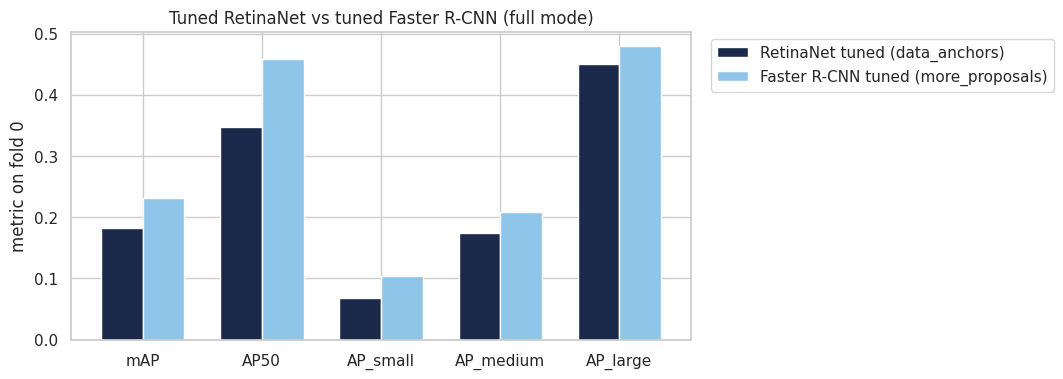

In [26]:
full_cmp = full_comparison
ax = full_cmp.T.plot.bar(color=[NAVY, LIGHT], figsize=(8, 4), rot=0, width=0.7)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set(ylabel="metric on fold 0", title="Tuned RetinaNet vs tuned Faster R-CNN (full mode)")
plt.show()

Faster R-CNN is better on every metric: mAP 0.2317 vs 0.1823 and AP_small 0.1041 vs 0.0676. The gap is biggest for small objects and smallest for large ones, so RetinaNet loses mostly on small objects.

## Submission

Predictions on the test frames in the competition format: one row per frame, "class score x y width height" for every box,
classes 0–7, x and y are the top-left corner in pixels of the original test frame. Test frames are read directly from the competition data.

In [27]:
@torch.no_grad()
def make_submission(model, path, batch=8):
    model.eval()
    test = pd.read_csv(DATA_DIR / "test_images.csv")
    rows = []
    for start in range(0, len(test), batch):
        part = test.iloc[start:start + batch]
        images = [torch.from_numpy(cv2.cvtColor(cv2.imread(str(DATA_DIR / f)), cv2.COLOR_BGR2RGB)).permute(2, 0, 1).float().div(255).to(DEVICE) for f in part["file_name"]]
        with torch.autocast(DEVICE.type, enabled=AMP):
            outputs = model(images)
        for image_id, o in zip(part["image_id"], outputs):
            boxes = o["boxes"].float().cpu().numpy()[:500]
            parts = [f"{l} {s:.4f} {x1:.1f} {y1:.1f} {x2 - x1:.1f} {y2 - y1:.1f}" for (x1, y1, x2, y2), l, s in zip(boxes, o["labels"].tolist()[:500], o["scores"].tolist()[:500])]
            rows.append({"image_id": image_id, "PredictionString": " ".join(parts)})
    pd.DataFrame(rows).to_csv(path, index=False)
    return path

Test frames are downloaded from Kaggle. The token is typed in when asked and is not saved in the notebook.

In [28]:
import os, getpass
if not os.environ.get("KAGGLE_API_TOKEN"):
    os.environ["KAGGLE_API_TOKEN"] = getpass.getpass("Kaggle token: ")
!pip install -q -U kaggle
!kaggle competitions download -c multiple-object-video-detection-hw-2-ucu-ai-2026 -p /content
!unzip -q -n /content/multiple-object-video-detection-hw-2-ucu-ai-2026.zip "test/*" "test_images.csv" -d /content/data

Kaggle token: ··········
100% 9.88G/9.88G [09:33<00:00, 18.5MB/s]



One submission for the final model (full mode) and one for every experiment in the cv mode. For each of them we used the model that was trained on folds 1–4 and validated on fold 0, so all submissions come from the same split and can be compared with each other.

In [29]:
SUBMISSIONS = [(final_name, "full")] + [(name, "cv") for name in EXPERIMENTS]
for name, mode in SUBMISSIONS:
    tag = f"{name}_{mode}_fold0"
    m = build_model(name, MODES[mode]["img_size"], 0)
    m.load_state_dict(torch.load(WORK_DIR / f"{tag}.pt", map_location=DEVICE))
    print(make_submission(m, WORK_DIR / f"submission_retinanet_{tag}.csv"))
    del m
    torch.cuda.empty_cache()

/content/drive/MyDrive/hw2/retinanet_v2/submission_retinanet_data_anchors_full_fold0.csv
/content/drive/MyDrive/hw2/retinanet_v2/submission_retinanet_baseline_cv_fold0.csv
/content/drive/MyDrive/hw2/retinanet_v2/submission_retinanet_data_anchors_cv_fold0.csv
/content/drive/MyDrive/hw2/retinanet_v2/submission_retinanet_focal_gamma3_cv_fold0.csv


## Conclusion

In cross-validation only data_anchors was a bit better than the baseline, with OOF mAP 0.0827 against 0.0813, while focal_gamma3 made everything worse, so we chose data_anchors as the final model. In our first attempt we made all anchor levels smaller, which helped small objects but cut AP_large to 0.111 and lowered OOF mAP to 0.055, so in the final version we changed only the first level, and even then most of the gain came from large objects and not from small ones. RetinaNet stayed clearly behind Faster R-CNN in both modes and the gap was largest for small objects, which fits the idea that without a proposal stage small objects are the hardest part.